# Session 12: ZeRO-1/2/3 Sharding Simulator (32 Virtual GPUs)

Simulates DP and ZeRO-1/2/3 on 32 virtual GPUs. Shows memory (state + activations, with explicit note) and computation (arithmetic + communication). Configurable.

References: Session 12 lecture (bytes/weight, P=2×N bf16, 2P vs 3P, reduce-scatter+all-gather equivalence).

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
from dataclasses import dataclass
from typing import Dict, List

GB = 1024**3
GiB = 1024**3  # gibibyte

## 1. Configuration (configurable)

In [2]:
# Configurable parameters
N_params_billion = 30.0  # e.g. 1.0, 7.0, 30.0
N_params = int(N_params_billion * 1e9)
G = 32  # number of virtual GPUs

# Precision (bytes per element)
bytes_w_bf16 = 2
bytes_g_bf16 = 2
bytes_master_fp32 = 4
bytes_m_fp32 = 4
bytes_v_fp32 = 4  # Adam m,v

# Activations estimate (optional, shown separately; excluded from ZeRO state sharding)
seq_len = 8192
batch_per_gpu = 1
hidden_size = 5120  # example, only for activation rough estimate
num_layers = 96  # example
act_dtype_bytes = 2  # bf16 activations typically stored in bf16/fp16 in practice; rough estimate

# H100 reference
h100_gib = 74.5

print('Config:')
print(f'  N = {N_params_billion}B ({N_params})')
print(f'  G = {G} virtual GPUs')
print(f'  seq_len={seq_len}, batch_per_gpu={batch_per_gpu}, hidden={hidden_size}, layers={num_layers}')

Config:
  N = 30.0B (30000000000)
  G = 32 virtual GPUs
  seq_len=8192, batch_per_gpu=1, hidden=5120, layers=96


## 2. State per weight and derived values

In [3]:
# Total bytes per weight when fully replicated (DP)
bytes_per_weight_dp_total = bytes_w_bf16 + bytes_g_bf16 + bytes_master_fp32 + bytes_m_fp32 + bytes_v_fp32
P_bytes = bytes_w_bf16 * N_params  # P = params in bf16

print('State model:')
print(f'  W={bytes_w_bf16} + G={bytes_g_bf16} + master={bytes_master_fp32} + m={bytes_m_fp32} + v={bytes_v_fp32} = {bytes_per_weight_dp_total} B/w')
print(f'  P (bf16 params) = {P_bytes/GB:.2f} GB ({P_bytes/GiB:.2f} GiB)')
print(f'  2P = {2*P_bytes/GB:.2f} GB per step (comm units)')
print(f'  3P = {3*P_bytes/GB:.2f} GB per step (comm units)')

State model:
  W=2 + G=2 + master=4 + m=4 + v=4 = 16 B/w
  P (bf16 params) = 55.88 GB (55.88 GiB)
  2P = 111.76 GB per step (comm units)
  3P = 167.64 GB per step (comm units)


## 3. Per-GPU memory by stage (state only; ZeRO shards W/G/Opt)

In [4]:
# Per-GPU state bytes
bytes_dp_pg = bytes_per_weight_dp_total * N_params
bytes_z1_pg = (bytes_w_bf16 + bytes_g_bf16) * N_params + (bytes_master_fp32 + bytes_m_fp32 + bytes_v_fp32) * (N_params / G)  # opt sharded
bytes_z2_pg = (bytes_w_bf16) * N_params + (bytes_g_bf16 + bytes_master_fp32 + bytes_m_fp32 + bytes_v_fp32) * (N_params / G)  # w full, g+opt sharded
bytes_z3_pg = bytes_per_weight_dp_total * (N_params / G)  # fully sharded

bw_dp = bytes_dp_pg / N_params if N_params > 0 else 0
bw_z1 = bytes_z1_pg / N_params if N_params > 0 else 0
bw_z2 = bytes_z2_pg / N_params if N_params > 0 else 0
bw_z3 = bytes_z3_pg / N_params if N_params > 0 else 0

rows = []
rows.append(('DP', bw_dp, bytes_dp_pg))
rows.append(('ZeRO-1', bw_z1, bytes_z1_pg))
rows.append(('ZeRO-2', bw_z2, bytes_z2_pg))
rows.append(('ZeRO-3', bw_z3, bytes_z3_pg))

import pandas as pd
df_state = pd.DataFrame(rows, columns=['Stage', 'B/w per GPU', 'State bytes per GPU'])
df_state['State GiB/GPU'] = df_state['State bytes per GPU'] / GiB
df_state['Fits H100 (74.5 GiB)?'] = df_state['State GiB/GPU'] <= h100_gib
df_state.round({'B/w per GPU': 3, 'State GiB/GPU': 2})

,Stage,B/w per GPU,State bytes per GPU,State GiB/GPU,Fits H100 (74.5 GiB)?
0,DP,16.000,4.800000e+11,447.03,False
1,ZeRO-1,4.375,1.312500e+11,122.24,False
2,ZeRO-2,2.438,7.312500e+10,68.10,True
3,ZeRO-3,0.500,1.500000e+10,13.97,True


## 4. Activations (excluded from ZeRO state sharding) — rough estimate

In [5]:
# Very rough activation estimate: per layer ~ batch*seq*hidden * bytes (and similar for others) — for illustration only
# Common rough: ~ batch*seq*hidden*num_layers * act_bytes (order-of-magnitude)
act_per_layer = batch_per_gpu * seq_len * hidden_size * act_dtype_bytes
act_total_rough = act_per_layer * num_layers
print('Activations (note: NOT sharded by ZeRO-1/2/3 state sharding):')
print(f'  Rough estimate (illustrative): ~{act_total_rough/GiB:.2f} GiB per GPU (depends on implementation/activation checkpointing)')
print('  ZeRO shards W,G,Opt only; activations are handled by SP/CP and scheduling later.')

Activations (note: NOT sharded by ZeRO-1/2/3 state sharding):
  Rough estimate (illustrative): ~7.50 GiB per GPU (depends on implementation/activation checkpointing)
  ZeRO shards W,G,Opt only; activations are handled by SP/CP and scheduling later.


## 5. Memory change visualization (state only)

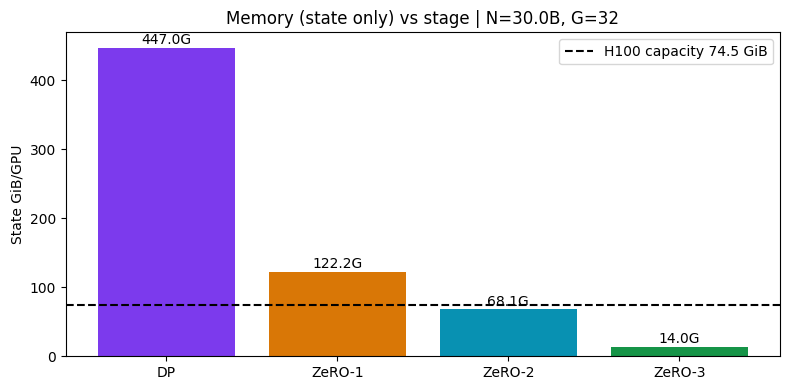

In [6]:
plt.figure(figsize=(8,4))
stages = ['DP','ZeRO-1','ZeRO-2','ZeRO-3']
vals = [df_state.iloc[i]['State GiB/GPU'] for i in range(4)]
colors = ['#7c3aed','#d97706','#0891b2','#159447']
bars = plt.bar(stages, vals, color=colors)
plt.axhline(h100_gib, linestyle='--', color='k', label=f'H100 capacity {h100_gib} GiB')
plt.ylabel('State GiB/GPU')
plt.title(f'Memory (state only) vs stage | N={N_params_billion}B, G={G}')
for b,v in zip(bars,vals):
    plt.text(b.get_x()+b.get_width()/2, v+1, f'{v:.1f}G', ha='center', va='bottom')
plt.legend()
plt.tight_layout()
plt.show()

## 6. Computation change: arithmetic + communication

In [7]:
# Arithmetic (conceptual): ~ 2*N*tokens per step total (rough constant)
tokens_per_step_total = seq_len * batch_per_gpu * G  # illustrative
flops_per_step_total_approx = 2.0 * N_params * tokens_per_step_total  # rough

# Communication: DP/Z1/Z2 = 2P, Z3 = 3P (bytes)
comm_dp_z1z2_P = 2.0
comm_z3_P = 3.0
comm_dp_z1z2_bytes = comm_dp_z1z2_P * P_bytes
comm_z3_bytes = comm_z3_P * P_bytes

comp = pd.DataFrame([
    ('DP', comm_dp_z1z2_P, comm_dp_z1z2_bytes, flops_per_step_total_approx),
    ('ZeRO-1', comm_dp_z1z2_P, comm_dp_z1z2_bytes, flops_per_step_total_approx),
    ('ZeRO-2', comm_dp_z1z2_P, comm_dp_z1z2_bytes, flops_per_step_total_approx),
    ('ZeRO-3', comm_z3_P, comm_z3_bytes, flops_per_step_total_approx),
], columns=['Stage','Comm (×P)','Comm bytes/step (total across G, conceptual)','FLOPs/step (total, approx)'])
comp['Comm GiB/step'] = comp['Comm bytes/step (total across G, conceptual)']/GiB
comp.round({'Comm (×P)':1,'Comm GiB/step':2})

,Stage,Comm (×P),"Comm bytes/step (total across G, conceptual)","FLOPs/step (total, approx)",Comm GiB/step
0,DP,2.0,1.200000e+11,1.572864e+16,111.76
1,ZeRO-1,2.0,1.200000e+11,1.572864e+16,111.76
2,ZeRO-2,2.0,1.200000e+11,1.572864e+16,111.76
3,ZeRO-3,3.0,1.800000e+11,1.572864e+16,167.64


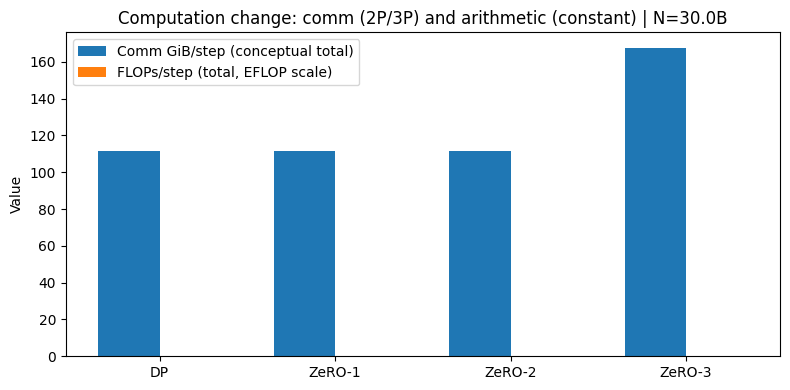

Notes:
  - DP/Z1/Z2: 2P (reduce-scatter + all-gather of gradients).
  - ZeRO-3: 3P (adds all-gather of weights in forward and again in backward).
  - Arithmetic FLOPs/step ~ 2*N*tokens total is roughly constant across stages; sharding changes placement, not total compute.


In [8]:
plt.figure(figsize=(8,4))
x = np.arange(4)
w = 0.35
plt.bar(x-w/2, [comp.iloc[i]['Comm GiB/step'] for i in range(4)], width=w, label='Comm GiB/step (conceptual total)', color='tab:blue')
plt.bar(x+w/2, [comp.iloc[i]['FLOPs/step (total, approx)']/1e18 for i in range(4)], width=w, label='FLOPs/step (total, EFLOP scale)', color='tab:orange')
plt.xticks(x, stages)
plt.ylabel('Value')
plt.title(f'Computation change: comm (2P/3P) and arithmetic (constant) | N={N_params_billion}B')
plt.legend()
plt.tight_layout()
plt.show()
print('Notes:')
print('  - DP/Z1/Z2: 2P (reduce-scatter + all-gather of gradients).')
print('  - ZeRO-3: 3P (adds all-gather of weights in forward and again in backward).')
print('  - Arithmetic FLOPs/step ~ 2*N*tokens total is roughly constant across stages; sharding changes placement, not total compute.')

## 7. Verification against lecture (G=8,30B and G=32,30B)

In [11]:
def bytes_pg_stage(Gg, Nn):
    dp = bytes_per_weight_dp_total*Nn
    z1 = (bytes_w_bf16+bytes_g_bf16)*Nn + (bytes_master_fp32+bytes_m_fp32+bytes_v_fp32)*(Nn/Gg)
    z2 = (bytes_w_bf16)*Nn + (bytes_g_bf16+bytes_master_fp32+bytes_m_fp32+bytes_v_fp32)*(Nn/Gg)
    z3 = bytes_per_weight_dp_total*(Nn/Gg)
    return dp,z1,z2,z3

def Nn_check(b): return int(b*1e9)

dp8,z18,z28,z38 = bytes_pg_stage(8, int(30e9))
dp32,z132,z232,z332 = bytes_pg_stage(32, int(30e9))

pd.DataFrame([
    ('G=8,30B', dp8/Nn_check(30), z18/Nn_check(30), z28/Nn_check(30), z38/Nn_check(30), dp8/GiB,z18/GiB,z28/GiB,z38/GiB),
    ('G=32,30B', dp32/Nn_check(30), z132/Nn_check(30), z232/Nn_check(30), z332/Nn_check(30), dp32/GiB,z132/GiB,z232/GiB,z332/GiB),
], columns=['Case','DP B/w','Z1 B/w','Z2 B/w','Z3 B/w','DP GiB/GPU','Z1 GiB/GPU','Z2 GiB/GPU','Z3 GiB/GPU']).round(3)

,Case,DP B/w,Z1 B/w,Z2 B/w,Z3 B/w,DP GiB/GPU,Z1 GiB/GPU,Z2 GiB/GPU,Z3 GiB/GPU
0,"G=8,30B",16.0,5.500,3.750,2.0,447.035,153.668,104.774,55.879
1,"G=32,30B",16.0,4.375,2.438,0.5,447.035,122.236,68.103,13.970
